# README results studio

Sample dataset photographs with a fixed seed, generate captions, and export comparison
panels for the README. These are **existing dataset images**, not synthesized images.
Every model sees the same selected images; selection never uses captions or scores.

Run cells in order. The default comparison uses the retained XE, REINFORCE, and SCST checkpoints
from the completed Pod runs. The optional charts use full saved
evaluations and histories, not scores computed on this illustrative subset.

From the repository root (local environment):
```bash
uv sync --extra notebook
uv run jupyter lab notebooks/readme_results.ipynb
```
On an already configured GPU Pod, use `uv run --no-sync jupyter lab` if Jupyter is installed.
Checkpoint mode may download the pinned tokenizer and ViT files on first use.
Saved mode needs dataset images and saved evaluation files, but does not load a model.


In [1]:
import os
import sys
from pathlib import Path

CONFIG_PATH = "configs/flickr30k-scst.toml"
SPLIT = "test"  # test or val; saved mode requires test
SEED = 42
SAMPLE_COUNT = 12
DECODINGS = ("greedy", "beam")
MODE = "checkpoint"  # "checkpoint" generates captions; "saved" reuses final evaluation
DEVICE = "auto"  # auto, cpu, mps, or cuda
BATCH_SIZE = 2
EXPORT_NAME = "flickr30k-all-models-seed42-v1"  # Change for a new experiment/export.
EVALUATION_DIR = Path("artifacts/final-evaluation/test")
ARTIFACTS_DIR = Path("artifacts")
MODELS = {
    "xe": Path("artifacts/flickr30k-xe-finetune-runpod/best.pt"),
    "reinforce": Path("artifacts/flickr30k-policy-gradient/reinforce/best.pt"),
    "scst": Path("artifacts/flickr30k-policy-gradient/scst/best.pt"),
}
MAKE_TEST_CHART = False  # Requires all six final evaluation cells.
MAKE_VALIDATION_CHART = True  # Requires both corrected RL histories.

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/scst_captioner").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Start Jupyter inside this repository.")


os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "scripts"))

## Load the corpus and freeze the selection

The selection file records the split/caption-file hashes and exact ordered image IDs.
Re-running with the same settings reuses that identity; changing the seed, count, or
corpus requires a new `EXPORT_NAME`. Caption outputs also refuse to replace different
results. No existing training or evaluation artifacts are modified.


In [2]:
import csv
import gc
import json
import textwrap
from dataclasses import replace

import matplotlib.pyplot as plt
import report_final_models as reporting
import torch
from IPython.display import Markdown, display
from PIL import Image

from scst_captioner import cli
from scst_captioner.checkpointing import load_model_checkpoint, sha256_file
from scst_captioner.config import load_config
from scst_captioner.data import SCSTImageDataset, collate_image_references, records_for_split
from scst_captioner.model import build_model
from scst_captioner.reproducibility import collect_environment, resolve_device, seed_everything

if MODE not in {"checkpoint", "saved"} or not MODELS:
    raise ValueError("Choose checkpoint/saved mode and at least one model.")
if not DECODINGS or any(d not in {"greedy", "beam"} for d in DECODINGS):
    raise ValueError("DECODINGS must contain greedy and/or beam.")
if SPLIT not in {"test", "val"} or (MODE == "saved" and SPLIT != "test"):
    raise ValueError("Choose test/val; saved final predictions require test.")
if BATCH_SIZE < 1 or SEED < 0 or Path(EXPORT_NAME).name != EXPORT_NAME:
    raise ValueError("Use a positive batch size, nonnegative seed, and a simple export name.")
base = load_config(CONFIG_PATH)
config = replace(
    base,
    data=replace(base.data, num_workers=0),
    runtime=replace(base.runtime, device=DEVICE, amp=False, seed=SEED, use_kv_cache=True),
)
records, manifest = cli._load_corpus(config)
split_records = records_for_split(records, manifest, SPLIT, validate=False)
if not 1 <= SAMPLE_COUNT <= len(split_records):
    raise ValueError(f"SAMPLE_COUNT must be between 1 and {len(split_records)}.")
selected_ids = reporting.select_examples([r.image_id for r in split_records], SAMPLE_COUNT, SEED)
by_id = {r.image_id: r for r in split_records}
selected_records = [by_id[i] for i in selected_ids]
OUTPUT = ROOT / "docs/results" / EXPORT_NAME
OUTPUT.mkdir(parents=True, exist_ok=True)


def save_json_once(path, value):
    if path.exists():
        if json.loads(path.read_text()) != value:
            raise ValueError(f"Different content already exists at {path}; change EXPORT_NAME.")
    else:
        path.write_text(json.dumps(value, indent=2, ensure_ascii=False) + "\n")


selection = {
    "seed": SEED,
    "count": SAMPLE_COUNT,
    "split": SPLIT,
    "algorithm": "random.Random(seed).sample(sorted(split_ids), count)",
    "split_manifest_sha256": sha256_file(config.data.split_manifest),
    "captions_file_sha256": sha256_file(config.data.captions_file),
    "image_ids": selected_ids,
    "image_sha256": {r.image_id: sha256_file(r.image_path) for r in selected_records},
}
save_json_once(OUTPUT / "selection.json", selection)
print(f"Selected {len(selected_ids)} {SPLIT} images → {OUTPUT}")
print(selected_ids)

Selected 12 test images → /Users/danielplotkin/Vault/image-captioning-with-scst/docs/results/flickr30k-all-models-seed42-v1
['45543081.jpg', '2072331027.jpg', '118865844.jpg', '4814335297.jpg', '2854959952.jpg', '2750185692.jpg', '2678668581.jpg', '2268207503.jpg', '4808471657.jpg', '202174004.jpg', '4687557453.jpg', '4814332291.jpg']


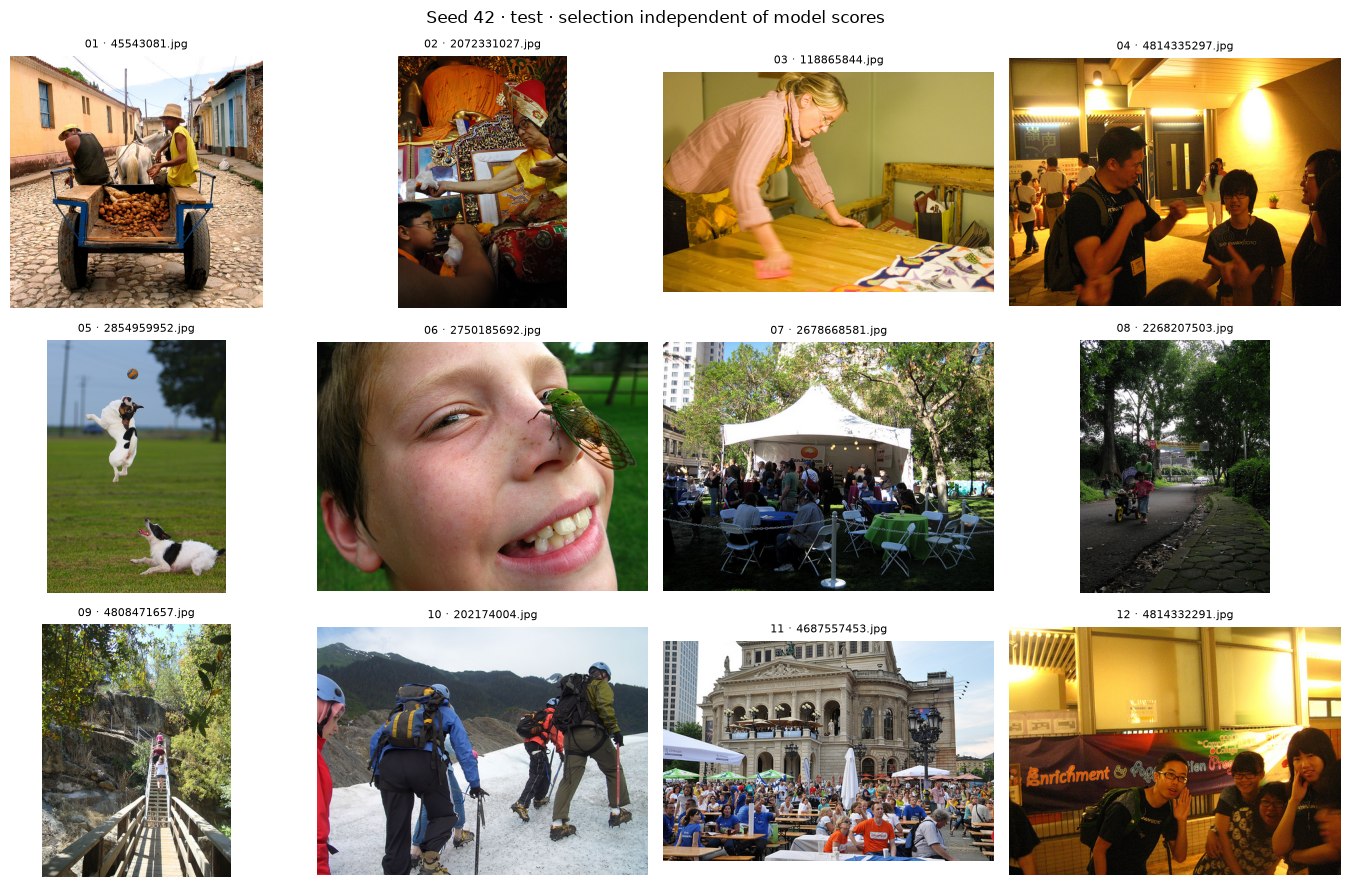

In [3]:
fig, axes = plt.subplots(
    (SAMPLE_COUNT + 3) // 4, 4, figsize=(14, 3 * ((SAMPLE_COUNT + 3) // 4)), squeeze=False
)
for ax in axes.flat:
    ax.axis("off")
for index, (ax, record) in enumerate(zip(axes.flat, selected_records, strict=False)):
    with Image.open(record.image_path) as source:
        ax.imshow(source.convert("RGB"))
    ax.set_title(f"{index + 1:02d} · {record.image_id}", fontsize=8)
fig.suptitle(f"Seed {SEED} · {SPLIT} · selection independent of model scores")
fig.tight_layout()
fig.savefig(OUTPUT / "contact-sheet.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## Generate or load captions

Checkpoint mode uses the CLI's checkpoint/data/protocol checks and inference routines,
with no optimizer or gradient updates. Models are loaded one at a time. FP32 and a small
batch are the default; the seed fixes selection, but exact numerical inference can vary
across devices. Beam settings and provenance are saved alongside captions.

Saved mode verifies prediction file hashes and full test-ID coverage before selecting
rows. It uses the original captions verbatim, including empty captions and EOS status.
Missing selected model files are errors; models are never silently omitted.


In [4]:
rows = []
sources = {}
device = resolve_device(DEVICE)
if MODE == "checkpoint":
    missing = [str(p) for p in MODELS.values() if not p.is_file()]
    if missing:
        raise FileNotFoundError(
            "Missing checkpoints; finish training or edit MODELS: " + ", ".join(missing)
        )
    model_configs = {
        name: replace(
            config, scst=replace(config.scst, baseline="none" if name == "reinforce" else "greedy")
        )
        for name in MODELS
    }
    summaries = {
        name: cli._preflight_checkpoint(
            str(path),
            expected_stage="xe" if name == "xe" else "scst",
            config=model_configs[name],
            manifest=manifest,
        )
        for name, path in MODELS.items()
    }
    hashes = {name: sha256_file(path) for name, path in MODELS.items()}
    if "xe" in hashes:
        for name, summary in summaries.items():
            if (
                name != "xe"
                and cli._recorded_xe_parent_sha256(summary["provenance"]) != hashes["xe"]
            ):
                raise ValueError(f"{name} does not descend from the supplied XE checkpoint.")
    seed_everything(SEED, deterministic=True)
    tokenizer, processor = cli._load_hf_components(config)
    dataset = SCSTImageDataset(
        selected_records,
        image_processor=processor,
        expected_references_per_image=config.data.expected_references_per_image,
    )
    loader = cli._loader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        config=config,
        collate_fn=collate_image_references,
    )
    for name, path in MODELS.items():
        print(f"Generating {name} on {device}...")
        model = build_model(config.model, tokenizer).to(device)
        checkpoint = load_model_checkpoint(model, path, map_location="cpu")
        del checkpoint
        try:
            with torch.inference_mode():
                for decoding in DECODINGS:
                    predictions, _, completed = cli._generate_records(
                        model,
                        loader,
                        tokenizer=tokenizer,
                        device=device,
                        config=config,
                        decoding=decoding,
                    )
                    rows.extend(
                        {
                            "image_id": p.image_id,
                            "model": name,
                            "decoding": decoding,
                            "caption": p.caption,
                            "completed": done,
                        }
                        for p, done in zip(predictions, completed, strict=True)
                    )
            sources[name] = {"checkpoint": str(path), "sha256": hashes[name]}
        finally:
            del model
            gc.collect()
            if device.type == "cuda":
                torch.cuda.empty_cache()
else:
    protocols = set()
    for name in MODELS:
        for decoding in DECODINGS:
            folder = EVALUATION_DIR / name / decoding
            payload = reporting.read_json(folder / "metrics.json")
            prediction_file = folder / "predictions.json"
            if sha256_file(prediction_file) != payload["prediction_artifact"]["sha256"]:
                raise ValueError(f"Prediction hash mismatch: {folder}")
            predictions = reporting.read_json(prediction_file)
            ids = [p["image_id"] for p in predictions]
            if len(ids) != len(set(ids)) or set(ids) != set(by_id):
                raise ValueError(f"Predictions do not cover the current test split: {folder}")
            context = payload["provenance"]["context"]
            if context["decoding"] != decoding:
                raise ValueError(f"Decoder mismatch: {folder}")
            if context["caption_records_sha256"] != manifest.records_sha256:
                raise ValueError(f"Reference corpus mismatch: {folder}")
            protocols.add(payload["provenance"]["comparison_protocol_sha256"])
            indexed = {p["image_id"]: p for p in predictions}
            rows.extend(
                {
                    "image_id": i,
                    "model": name,
                    "decoding": decoding,
                    "caption": indexed[i]["caption"],
                    "completed": indexed[i]["completed"],
                }
                for i in selected_ids
            )
            sources[f"{name}/{decoding}"] = {
                "path": str(folder),
                "metrics_sha256": sha256_file(folder / "metrics.json"),
                "predictions_sha256": sha256_file(prediction_file),
                "context": context,
            }
    if len(protocols) != 1:
        raise ValueError("Saved evaluations use different corpus/metric protocols.")

bundle = {
    "selection": selection,
    "mode": MODE,
    "sources": sources,
    "generation_config": {name: cfg.to_dict() for name, cfg in model_configs.items()}
    if MODE == "checkpoint"
    else None,
    "device": str(device) if MODE == "checkpoint" else None,
    "batch_size": BATCH_SIZE if MODE == "checkpoint" else None,
    "references": {r.image_id: list(r.captions) for r in selected_records},
    "captions": rows,
}
save_json_once(OUTPUT / "captions.json", bundle)
if not (OUTPUT / "environment.json").exists():
    save_json_once(OUTPUT / "environment.json", collect_environment(ROOT))
with (OUTPUT / "captions.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(
        stream, fieldnames=["image_id", "model", "decoding", "caption", "completed"]
    )
    writer.writeheader()
    writer.writerows(rows)
print(f"Saved {len(rows)} captions to captions.json and captions.csv")

Generating xe on mps...
Generating reinforce on mps...
Generating scst on mps...
Saved 72 captions to captions.json and captions.csv


## Export comparison panels and a README snippet

One panel per image shows every selected model/decoder and all human references.
Text is wrapped and panel height adapts to caption length. The first three sampled
images appear in the generated Markdown snippet, without score-based selection.
JSON and CSV retain the full captions for later layouts or analysis.


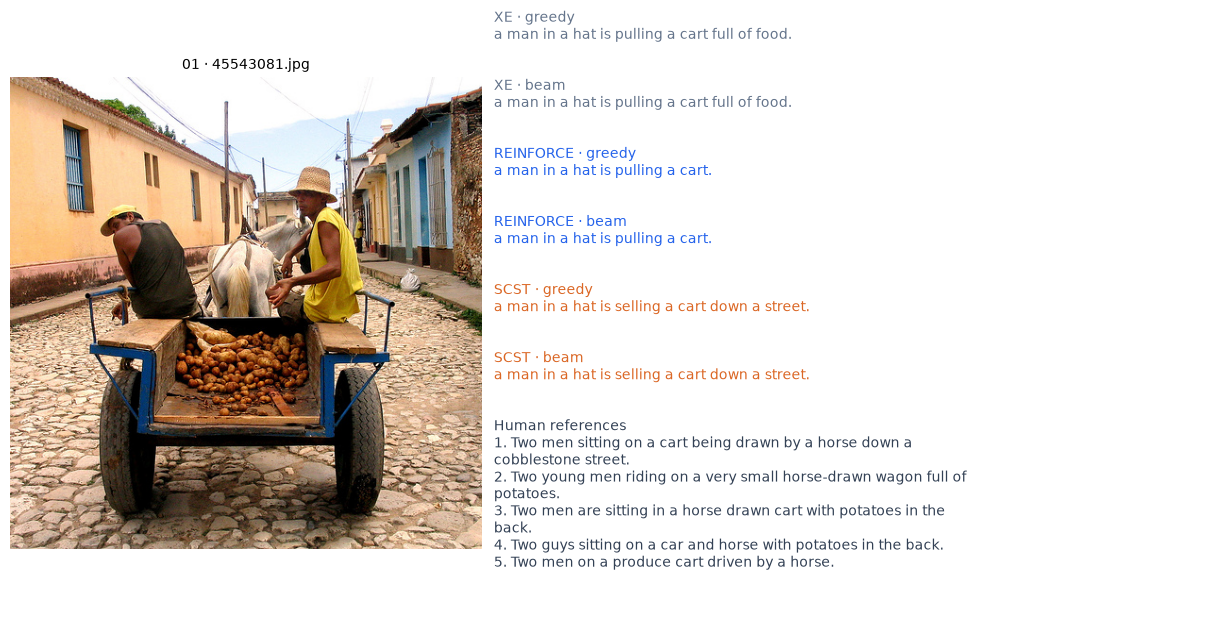

```markdown
Illustrative test images sampled with seed 42; not aggregate evaluation.

![Model caption comparison](docs/results/flickr30k-all-models-seed42-v1/example-01.png)

![Model caption comparison](docs/results/flickr30k-all-models-seed42-v1/example-02.png)

![Model caption comparison](docs/results/flickr30k-all-models-seed42-v1/example-03.png)

```

Copy readme-snippet.md into the root README when ready.


In [5]:
panel_names = []
for index, record in enumerate(selected_records):
    image_rows = [row for row in rows if row["image_id"] == record.image_id]
    blocks = []
    for row in image_rows:
        label = reporting.LABELS.get(row["model"], row["model"])
        caption = row["caption"] or "[empty caption]"
        if not row["completed"]:
            caption += " [length limit]"
        blocks.append(
            (
                f"{label} · {row['decoding']}\n" + textwrap.fill(caption, 68),
                reporting.COLORS.get(row["model"], "#334155"),
            )
        )
    blocks.append(
        (
            "Human references\n"
            + "\n".join(
                textwrap.fill(f"{i + 1}. {caption}", 68)
                for i, caption in enumerate(record.captions)
            ),
            "#334155",
        )
    )
    heights = [text.count("\n") + 2 for text, _ in blocks]
    fig = reporting.figure((12, max(5, sum(heights) * 0.22)))
    grid = fig.add_gridspec(len(blocks), 2, width_ratios=[1, 1.5], height_ratios=heights)
    ax = fig.add_subplot(grid[:, 0])
    with Image.open(record.image_path) as source:
        ax.imshow(source.convert("RGB"))
    ax.axis("off")
    ax.set_title(f"{index + 1:02d} · {record.image_id}", fontsize=10)
    for n, (text, color) in enumerate(blocks):
        ax = fig.add_subplot(grid[n, 1])
        ax.axis("off")
        ax.text(0, 1, text, va="top", fontsize=10, color=color)
    panel_name = f"example-{index + 1:02d}.png"
    fig.savefig(OUTPUT / panel_name, dpi=180, bbox_inches="tight", facecolor="white")
    if index == 0:
        display(fig)
    fig.clear()
    panel_names.append(panel_name)

snippet = f"Illustrative {SPLIT} images sampled with seed {SEED}; not aggregate evaluation.\n\n"
for name in panel_names[:3]:
    snippet += f"![Model caption comparison]({OUTPUT.relative_to(ROOT).as_posix()}/{name})\n\n"
(OUTPUT / "readme-snippet.md").write_text(snippet)
display(Markdown("```markdown\n" + snippet + "```"))
print("Copy readme-snippet.md into the root README when ready.")

## Optional quantitative comparisons

Enable the switches in the settings cell only after corrected training/evaluation.
These reuse `scripts/report_final_models.py`: the test chart expects XE, REINFORCE,
and SCST × greedy/beam-3, on the complete 1,000-image Flickr30k test split. The validation
chart shows greedy training-corpus CIDEr-D and the common XE baseline. It is a different
protocol from COCO CIDEr; the two are labeled separately. No subset scores are presented
as benchmark results. Missing inputs produce an actionable error rather than fake charts.


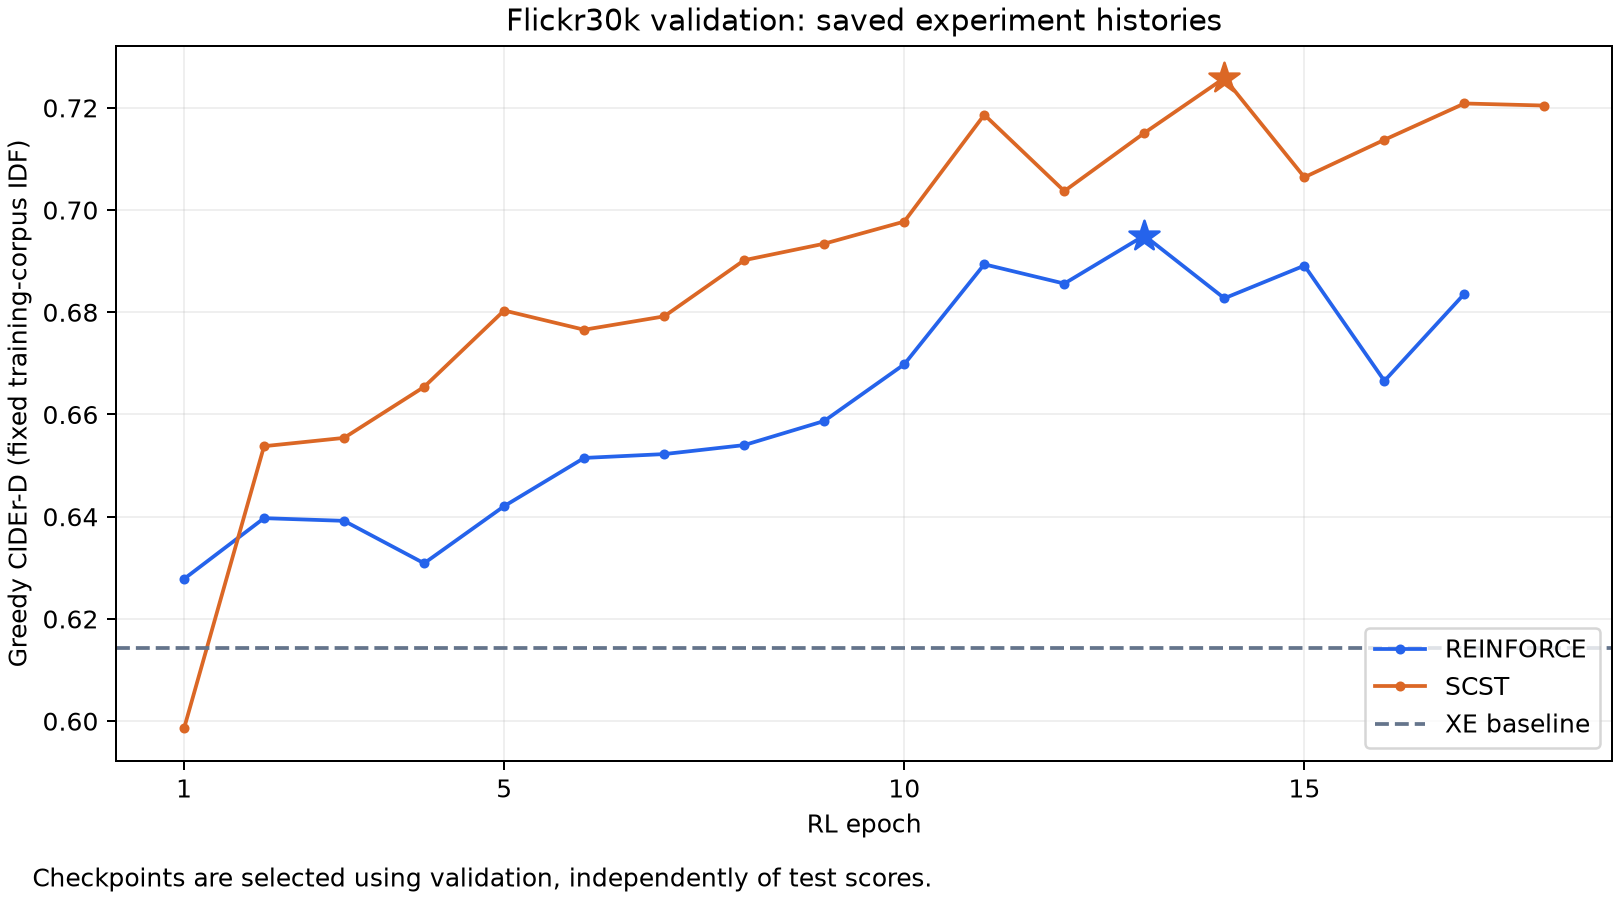

In [6]:
if MAKE_TEST_CHART:
    comparison_path = EVALUATION_DIR / "comparison.json"
    if not comparison_path.is_file():
        raise FileNotFoundError("Run scripts/evaluate_final_models.py after training first.")
    comparison = reporting.read_json(comparison_path)
    cells = [comparison["cells"][m][d] for m in reporting.METHODS for d in ("greedy", "beam")]
    if len({c["provenance"]["comparison_protocol_sha256"] for c in cells}) != 1:
        raise ValueError("Test cells have different comparison protocols.")
    for c in cells:
        context = c["provenance"]["context"]
        if (
            c["provenance"]["num_images"] != 1000
            or context["caption_records_sha256"] != manifest.records_sha256
        ):
            raise ValueError("Expected the full current Flickr30k test corpus.")
        if context["decoding"] == "beam" and (
            context["beam_size"] != 3 or context["length_penalty_alpha"] != 0.7
        ):
            raise ValueError("The reporting chart assumes beam-3, length penalty 0.7.")
    save_json_once(
        OUTPUT / "test-source.json",
        {"path": str(comparison_path), "sha256": sha256_file(comparison_path)},
    )
    reporting.test_chart(comparison, OUTPUT)
    display(Image.open(OUTPUT / "test-metrics.png"))

if MAKE_VALIDATION_CHART:
    required = [
        ARTIFACTS_DIR / "flickr30k-policy-gradient" / m / f
        for m in ("reinforce", "scst")
        for f in ("history.json", "xe_validation.json")
    ]
    if any(not p.is_file() for p in required):
        raise FileNotFoundError(
            "Both corrected RL histories and XE validation baselines are required."
        )
    save_json_once(OUTPUT / "validation-source.json", {str(p): sha256_file(p) for p in required})
    reporting.validation_chart(ARTIFACTS_DIR, OUTPUT)
    display(Image.open(OUTPUT / "validation-reward.png"))

if not MAKE_TEST_CHART and not MAKE_VALIDATION_CHART:
    print(
        "Quantitative charts disabled. Enable them when full evaluation/history artifacts are ready."
    )